# Sales & Demand Forecasting — Analysis

EDA and a head-to-head comparison of an **LSTM** against **Holt-Winters** and **SARIMA** for monthly sales forecasting. The goal is not just to fit a deep model but to show *which* model the data actually justifies.

In [1]:
import sys, os
sys.path.append('..')
import warnings; warnings.filterwarnings('ignore')
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from src.data import generate_sample_sales, load_series
from src.models import compare_models
plt.rcParams['figure.figsize'] = (10, 4)

df = generate_sample_sales()
series = load_series(df, 'date', 'sales')
df.head()

,date,sales
0,2020-01-01,8013.0
1,2020-02-01,7547.0
2,2020-03-01,9785.0
3,2020-04-01,11198.0
4,2020-05-01,10454.0


## 1. Exploratory analysis

The series shows a clear upward **trend** and a repeating yearly **seasonal** pattern with a December spike — the two structures any forecaster must capture.

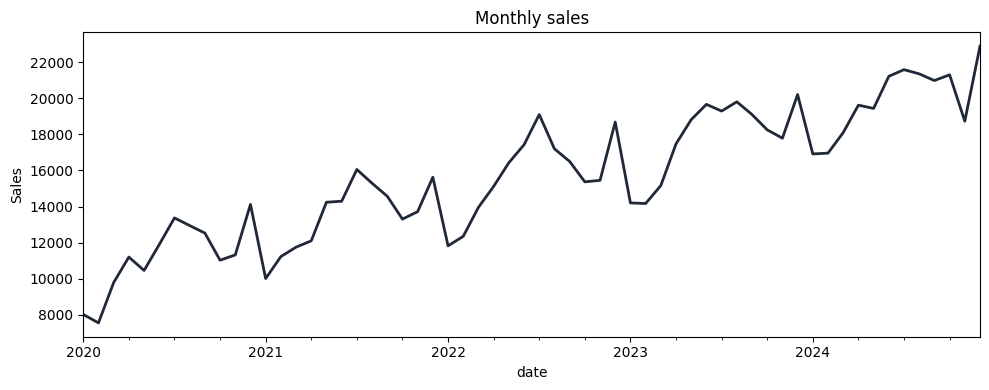

In [2]:
ax = series.plot(color='#1f2937', lw=2)
ax.set_title('Monthly sales'); ax.set_ylabel('Sales'); plt.tight_layout(); plt.show()

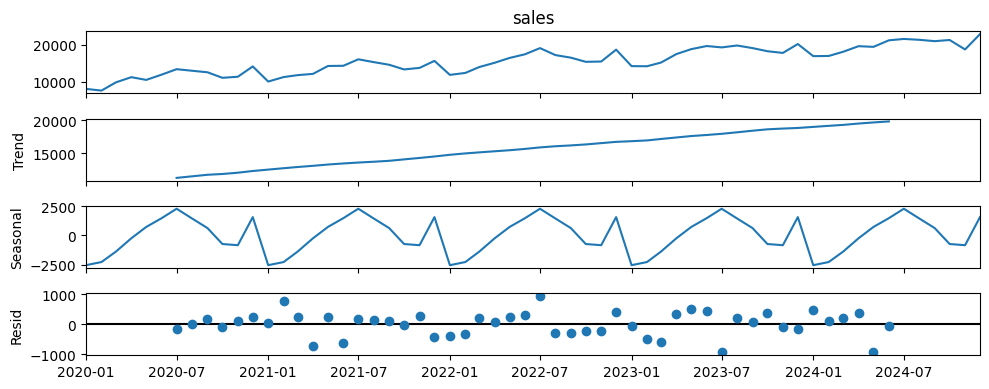

In [3]:
from statsmodels.tsa.seasonal import seasonal_decompose
seasonal_decompose(series, model='additive', period=12).plot(); plt.tight_layout(); plt.show()

## 2. Back-test: LSTM vs classical baselines

Every model is fit on all but the last 12 months and scored on that held-out year (**MAPE** = avg % error, **RMSE** = error in sales units). Lower is better.

In [4]:
results = compare_models(series, horizon=6)
metrics = pd.DataFrame([{'Model': r['name'], **r['metrics']} for r in results])\
            .sort_values('MAPE').reset_index(drop=True)
metrics

I0000 00:00:1781861314.645870    1828 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1781861317.167562    1828 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


,Model,MAPE,RMSE
0,Holt-Winters,2.66,712.5
1,SARIMA,2.99,718.6
2,LSTM,5.96,1458.0


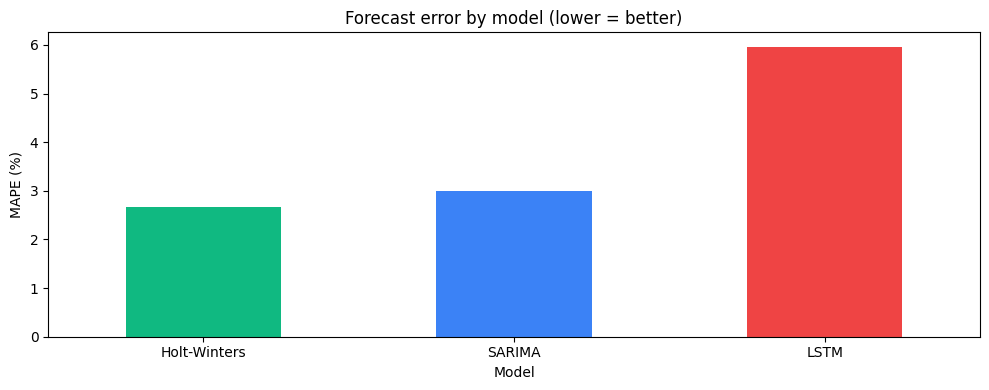

In [5]:
ax = metrics.set_index('Model')['MAPE'].plot.bar(color=['#10b981','#3b82f6','#ef4444'], rot=0)
ax.set_ylabel('MAPE (%)'); ax.set_title('Forecast error by model (lower = better)')
plt.tight_layout(); plt.show()

## 3. Forecasts for the next 6 months

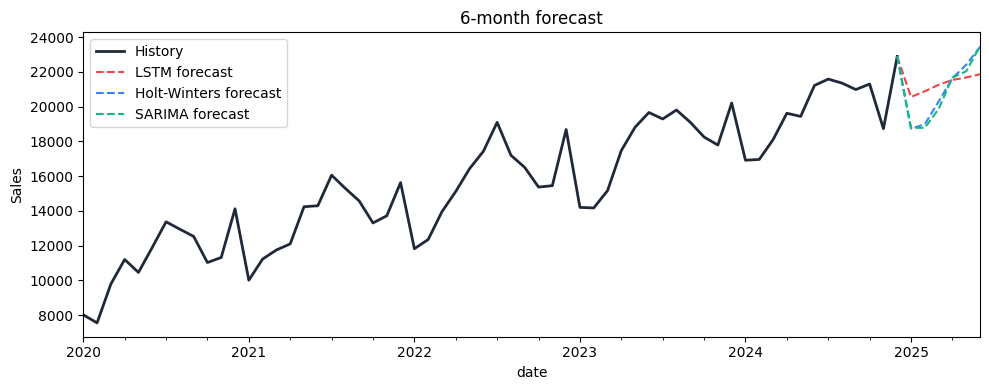

In [6]:
fig, ax = plt.subplots()
series.plot(ax=ax, color='#1f2937', lw=2, label='History')
colors = {'LSTM':'#ef4444','Holt-Winters':'#3b82f6','SARIMA':'#10b981'}
for r in results:
    f = r['future']
    link = pd.concat([series.iloc[[-1]], f])
    link.plot(ax=ax, ls='--', color=colors[r['name']], label=f"{r['name']} forecast")
ax.legend(); ax.set_ylabel('Sales'); ax.set_title('6-month forecast'); plt.tight_layout(); plt.show()

## Conclusion

On ~60 monthly observations the **classical models (Holt-Winters, SARIMA) beat the LSTM**. This is expected: deep recurrent nets need far more data to outperform well-specified statistical models, and a short business series doesn't provide it. The practical recommendation for this dataset is Holt-Winters — and the value of the exercise is *demonstrating* that with a fair back-test rather than assuming deep learning wins. As history grows, re-running this comparison is the right way to decide when an LSTM starts to pay off.